# Creating the ARIMA baseline models

In [1]:
import pandas as pd
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import joblib

sys.path.append('../')

from model_recurrent import Model

In [2]:
df = pd.read_csv("../full_data.csv")

In [3]:
model0 = Model(df, "101")
X_combined, y_combined, X_train, X_test, y_test, test, pds, epsilon = model0.partition()
model0.arima_base(y_combined, y_test, epsilon)

                                      SARIMAX Results                                      
Dep. Variable:                                   y   No. Observations:                  252
Model:             SARIMAX(0, 1, 1)x(1, 0, [], 52)   Log Likelihood                -150.265
Date:                             Wed, 02 Sep 2026   AIC                            306.529
Time:                                     17:28:33   BIC                            317.106
Sample:                                 01-05-2020   HQIC                           310.785
                                      - 10-27-2024                                         
Covariance Type:                               opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.7193      0.038    -18.896      0.000      -0.794      -0.645
ar.S.L52       0.2588      

Auto ARIMA NRMSE: 0.5073


Text(0, 0.5, 'Relative risk')

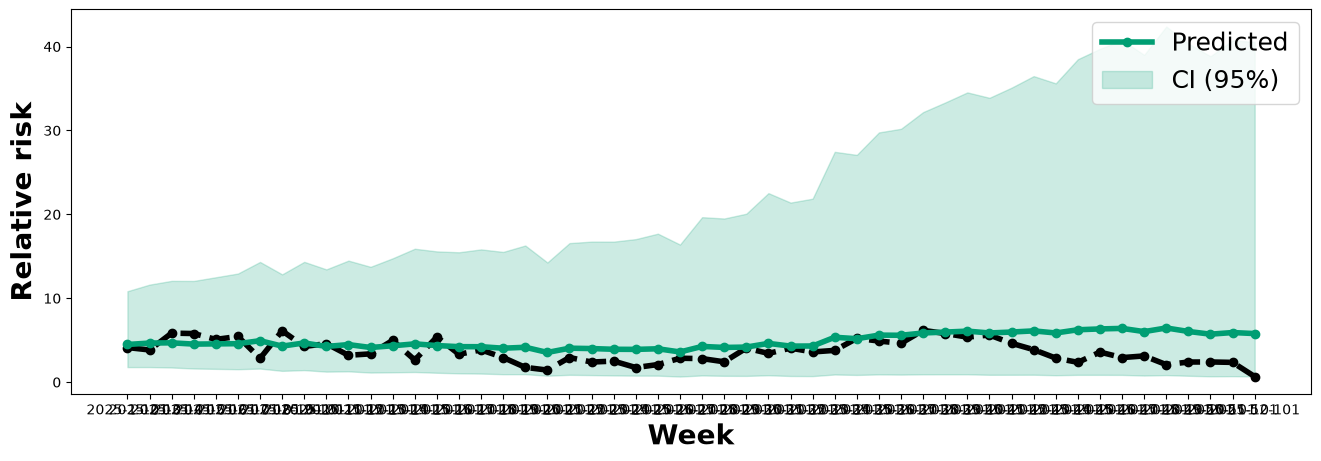

In [5]:
import numpy as np
from sklearn.metrics import root_mean_squared_error
model = joblib.load(f"../saved_models/arima/101_arima.joblib")
model0 = Model(df, "101")

df_copy = df[df["week_canton"].str.contains("101")]
week_canton = df['week_canton'] 
X_combined, y_combined, X_train, X_test, y_test, test, pds, epsilon = model0.partition()

forecast, conf_int = model.predict(n_periods=len(y_test), return_conf_int=True)

forecast_series = pd.Series(forecast, index=None)

y_pred = np.exp(forecast_series) - epsilon
y_true = np.exp(y_test) - epsilon

lower_bound = np.exp(conf_int[:, 0]) - epsilon
upper_bound = np.exp(conf_int[:, 1]) - epsilon

rmse = root_mean_squared_error(y_true, y_pred)
nrmse = rmse / (np.mean(y_true) + epsilon)
print(f"Auto ARIMA NRMSE: {nrmse:.4f}")

fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(df_copy['week_canton'].iloc[len(y_combined):], y_true, marker='o', linestyle = "dashed", color = "#000000", linewidth=4)
ax.plot(df_copy['week_canton'].iloc[len(y_combined):], y_pred, label='Predicted', marker='o',linestyle = "solid", color = "#009E73", linewidth=4)
ax.fill_between(x = df_copy['week_canton'].iloc[len(y_combined):], label = "CI (95%)", y1 = lower_bound, y2 = upper_bound, alpha = 0.2, color = "#009E73")
ax.legend(loc = "upper right", fontsize = 18)
ax.set_xlabel('Week', fontweight = "bold", fontsize = 20)
ax.set_ylabel(f'Relative risk', fontweight = "bold", fontsize = 20)


In [7]:
df_copy.shape

(304, 263)

In [6]:
forecast_series

0     1.730592e+15
1     1.731197e+15
2     1.731802e+15
3     1.732406e+15
4     1.733011e+15
5     1.733616e+15
6     1.734221e+15
7     1.734826e+15
8     1.735430e+15
9     1.736035e+15
10    1.736640e+15
11    1.737245e+15
12    1.737850e+15
13    1.738454e+15
14    1.739059e+15
15    1.739664e+15
16    1.740269e+15
17    1.740874e+15
18    1.741478e+15
19    1.742083e+15
20    1.742688e+15
21    1.743293e+15
22    1.743898e+15
23    1.744502e+15
24    1.745107e+15
25    1.745712e+15
26    1.746317e+15
27    1.746922e+15
28    1.747526e+15
29    1.748131e+15
30    1.748736e+15
31    1.749341e+15
32    1.749946e+15
33    1.750550e+15
34    1.751155e+15
35    1.751760e+15
36    1.752365e+15
37    1.752970e+15
38    1.753574e+15
39    1.754179e+15
40    1.754784e+15
41    1.755389e+15
42    1.755994e+15
43    1.756598e+15
44    1.757203e+15
45    1.757808e+15
46    1.758413e+15
47    1.759018e+15
48    1.759622e+15
49    1.760227e+15
50    1.760832e+15
51    1.761437e+15
dtype: float